# 1 · Librerías
`torch` para las redes y el entrenamiento, `numpy` y `pandas` para tablas, `matplotlib` para los gráficos, `ipywidgets` para los sliders y `Path` para guardar archivos. Todo viene preinstalado en Google Colab.

In [27]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

print("torch", torch.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

torch 2.11.0+cu130 | numpy 2.1.3 | pandas 2.2.3


# 2 · Parámetros
Valores que fijé tras un ajuste previo con una semilla distinta de las de evaluación (ver `ajuste_hiperparametros.py` en la carpeta de código):

- **`SESGO_OLVIDO = 2.0`:** inicializar el sesgo de la compuerta de olvido en 1 o 2 es una práctica común para facilitar el flujo del gradiente (Rehmer y Kroll, 2022; Tolić et al., 2024, que citan a Jozefowicz et al.). En mi ajuste, con 1.0 la LSTM falló con tasas de aprendizaje altas y con 2.0 no.
- **Radio 1.0 de `Wh`:** matriz recurrente ortogonal, cuyos autovalores tienen módulo 1. El radio es el parámetro que variaré en el Panel A (Dou y Principe, 2023, analizan el decaimiento de la información según los autovalores de `Wh`).
- **`UMBRAL_CLIP = 1.0`:** norma máxima del gradiente para la variante con recorte (técnica de la Clase 11).

Las redes son pequeñas, así que uso CPU.

In [28]:
N_CLASES = 4          # clases que la red debe recordar
OCULTAS = 32          # unidades ocultas
LOTE = 64
PASOS = 3000          # pasos de Adam por entrenamiento
LR = 0.005
UMBRAL_CLIP = 1.0
SESGO_OLVIDO = 2.0
RUIDO = 0.5           # desviación estándar del ruido entre t=1 y t=T-1
SEMILLAS = [0, 1, 2]
LONGITUDES = [5, 10, 20, 30, 50, 80]
N_PRUEBA = 2000
DISPOSITIVO = torch.device("cpu")

SALIDA = Path("resultados_s11")
SALIDA.mkdir(exist_ok=True)
print("Se guardarán los archivos en:", SALIDA.resolve())

Se guardarán los archivos en: /content/resultados_s11


# 3 · Aritmética de la lámina
En la Clase 11, con activación lineal, la derivada del estado final respecto del primero es `w^(T−1)`. La lámina calcula `1.1^50 ≈ 117.4` y `0.9^50 ≈ 0.005`, pero usa el exponente 50 aunque la fórmula pide `T−1 = 49`. Calculo ambos para ver cuánto cambia.

In [29]:
filas = []
for w in (1.1, 0.9):
    filas.append({"w": w, "T": 50, "w^50 (lámina)": w ** 50, "w^49 (fórmula)": w ** 49})
aritmetica = pd.DataFrame(filas)
display(aritmetica)

,w,T,w^50 (lámina),w^49 (fórmula)
0,1.1,50,117.390853,106.718957
1,0.9,50,0.005154,0.005726


# 4 · La tarea: recordar la clase del primer paso
La secuencia tiene `T` pasos. En `t = 0` se muestra la clase (uno de 4 valores, codificada one-hot) junto con un indicador; en los `T − 1` pasos siguientes solo llega ruido gaussiano. Al final, la red debe decir cuál fue la clase. Para acertar, la información tiene que viajar `T − 1` pasos, así que la dificultad crece con `T` y el azar es 25 %.

Esta tarea es de mi diseño: sirve para aislar la dependencia a largo plazo, no viene de las fuentes.

In [30]:
def generar(n, T, gen):
    # X: (T, n, N_CLASES + 1). En t=0: one-hot de la clase + indicador; en t>0: ruido.
    y = torch.randint(0, N_CLASES, (n,), generator=gen)
    X = RUIDO * torch.randn(T, n, N_CLASES + 1, generator=gen)
    X[0] = 0.0
    X[0, torch.arange(n), y] = 1.0
    X[0, :, N_CLASES] = 1.0
    X[1:, :, N_CLASES] = 0.0
    return X.to(DISPOSITIVO), y.to(DISPOSITIVO)

## 4 · b · Un ejemplo
Reviso la forma de los datos y una muestra: el primer paso debe contener la clase y los demás solo ruido.

In [31]:
gen_demo = torch.Generator().manual_seed(0)
X_demo, y_demo = generar(3, 6, gen_demo)
print("forma de X (T, lote, canales):", tuple(X_demo.shape), "| etiquetas:", y_demo.tolist())
print("t = 0 de la muestra 0:", X_demo[0, 0].tolist())
print("t = 1 de la muestra 0:", [round(v, 2) for v in X_demo[1, 0].tolist()])

forma de X (T, lote, canales): (6, 3, 5) | etiquetas: [0, 3, 1]
t = 0 de la muestra 0: [1.0, 0.0, 0.0, 0.0, 1.0]
t = 1 de la muestra 0: [0.39, 0.4, 0.3, -0.78, 0.0]


# 5 · Los dos modelos
- **RNN simple:** `h_t = tanh(W_ih x_t + W_hh h_{t-1} + b)`, la red de la Clase 11. Inicializo `W_hh` ortogonal con el radio indicado y los sesgos en 0 (la ortogonalidad se menciona en Ceni, 2025, como inicialización usada para entrenar redes muy profundas, aunque no resuelve por sí sola el problema).
- **LSTM:** celda de memoria con compuertas de entrada, olvido y salida (Clase 11). Sesgo de olvido inicial `SESGO_OLVIDO`.

Los dos usan las capas `nn.RNN` y `nn.LSTM` de PyTorch, y una capa lineal sobre el último estado oculto para predecir la clase.

In [32]:
class RNNSimple(nn.Module):
    def __init__(self, radio=1.0):
        super().__init__()
        self.rnn = nn.RNN(N_CLASES + 1, OCULTAS, nonlinearity="tanh")
        self.salida = nn.Linear(OCULTAS, N_CLASES)
        with torch.no_grad():
            nn.init.orthogonal_(self.rnn.weight_hh_l0, gain=radio)
            self.rnn.bias_ih_l0.zero_()
            self.rnn.bias_hh_l0.zero_()

    def forward(self, X):
        salidas, _ = self.rnn(X)
        return self.salida(salidas[-1])


class LSTMModelo(nn.Module):
    def __init__(self, sesgo_olvido=SESGO_OLVIDO):
        super().__init__()
        self.rnn = nn.LSTM(N_CLASES + 1, OCULTAS)
        self.salida = nn.Linear(OCULTAS, N_CLASES)
        with torch.no_grad():
            self.rnn.bias_ih_l0.zero_()
            self.rnn.bias_hh_l0.zero_()
            # orden de compuertas en PyTorch: entrada, olvido, candidato, salida
            self.rnn.bias_ih_l0[OCULTAS:2 * OCULTAS] = sesgo_olvido

    def forward(self, X):
        salidas, _ = self.rnn(X)
        return self.salida(salidas[-1])


def crear(nombre, radio=1.0):
    return (LSTMModelo() if nombre == "LSTM" else RNNSimple(radio)).to(DISPOSITIVO)

## 5 · b · Tamaño de cada modelo
Cuento los parámetros para tener presente la diferencia de capacidad entre ambos.

In [33]:
for nombre in ("RNN", "LSTM"):
    m = crear(nombre)
    print(f"{nombre:<5} parámetros: {sum(p.numel() for p in m.parameters())}")

RNN   parámetros: 1380
LSTM  parámetros: 5124


# 6 · Medir el gradiente en cada paso temporal
Quiero saber cuánto gradiente llega a cada paso `t`, es decir `‖dL/dh_t‖`, no solo el gradiente de los parámetros. `nn.RNN` y `nn.LSTM` no devuelven esos gradientes intermedios, así que recorro la secuencia paso a paso con los mismos pesos del modelo, pido que PyTorch conserve el gradiente de cada `h_t` (`retain_grad`) y llamo a `backward` una vez.

La razón entre el gradiente del primer paso y el del último, `‖dL/dh_1‖ / ‖dL/dh_T‖`, resume el desvanecimiento (valores muy menores que 1) o la explosión (valores mucho mayores que 1). Esa multiplicación repetida de jacobianos es la explicación de la Clase 11, y Ceni (2025, p. 10794) la describe como un producto secuencial de matrices cuya norma puede reducirse o crecer exponencialmente.

In [34]:
def recorrer(modelo, X):
    # Recorre la secuencia con los pesos del modelo y devuelve los estados ocultos y el último.
    T, B, _ = X.shape
    r = modelo.rnn
    h = torch.zeros(B, OCULTAS, device=X.device)
    c = torch.zeros(B, OCULTAS, device=X.device)
    estados = []
    for t in range(T):
        a = X[t] @ r.weight_ih_l0.T + r.bias_ih_l0 + h @ r.weight_hh_l0.T + r.bias_hh_l0
        if isinstance(r, nn.LSTM):
            i, f, g, o = a.chunk(4, dim=1)
            c = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
            h = torch.sigmoid(o) * torch.tanh(c)
        else:
            h = torch.tanh(a)
        h.retain_grad()
        estados.append(h)
    return estados, h


def normas_gradiente(modelo, X, y):
    # Norma de dL/dh_t por muestra, promediada, para t = 1..T.
    estados, h_final = recorrer(modelo, X)
    modelo.zero_grad()
    F.cross_entropy(modelo.salida(h_final), y).backward()
    return torch.stack([e.grad.norm(dim=1).mean() for e in estados]).detach().cpu().numpy()

## 6 · b · Verificaciones
Antes de confiar en las medidas compruebo tres cosas, con `assert`:

1. El recorrido manual produce las mismas salidas que `nn.RNN` y `nn.LSTM`.
2. El gradiente de los pesos calculado por el recorrido manual coincide con el del modelo original.
3. En el caso lineal escalar, el gradiente automático de `h_T` respecto de `h_1` es `w^(T−1)`, como dice la lámina.

In [35]:
torch.manual_seed(0)
X_v, y_v = generar(16, 12, torch.Generator().manual_seed(1))
for nombre in ("RNN", "LSTM"):
    m = crear(nombre)
    # 1. mismas salidas
    _, h_fin = recorrer(m, X_v)
    assert torch.allclose(m.salida(h_fin), m(X_v), atol=1e-5), f"salida distinta en {nombre}"
    # 2. mismo gradiente de pesos
    m.zero_grad()
    F.cross_entropy(m(X_v), y_v).backward()
    g_modelo = m.rnn.weight_hh_l0.grad.clone()
    normas_gradiente(m, X_v, y_v)
    g_manual = m.rnn.weight_hh_l0.grad.clone()
    assert torch.allclose(g_modelo, g_manual, atol=1e-5), f"gradiente distinto en {nombre}"
    print(f"{nombre}: recorrido manual y modelo coinciden (salidas y gradiente)")

# 3. caso lineal escalar: dh_T/dh_1 = w^(T-1)
for w in (1.1, 0.9):
    h1 = torch.tensor(1.0, dtype=torch.float64, requires_grad=True)
    h = h1
    for _ in range(49):
        h = w * h
    h.backward()
    assert abs(h1.grad.item() - w ** 49) < 1e-9 * max(1.0, w ** 49)
    print(f"w = {w}: dh_T/dh_1 automático = {h1.grad.item():.5f} = w^49 = {w ** 49:.5f}")

RNN: recorrido manual y modelo coinciden (salidas y gradiente)
LSTM: recorrido manual y modelo coinciden (salidas y gradiente)
w = 1.1: dh_T/dh_1 automático = 106.71896 = w^49 = 106.71896
w = 0.9: dh_T/dh_1 automático = 0.00573 = w^49 = 0.00573


# 7 · Panel A: el gradiente según la distancia, sin entrenar
Con este panel muestro el desvanecimiento y la explosión en vivo, sin entrenar nada: se crea la red con los pesos iniciales y se mide `‖dL/dh_t‖ / ‖dL/dh_T‖` en cada paso.

- **Radio de `W_hh`:** escala la matriz recurrente ortogonal. Con radio menor que 1 los autovalores contraen la información y con radio mayor que 1 la amplían; Dou y Principe (2023) analizan ese decaimiento con la descomposición en autovalores de `W_hh` y señalan que en un sistema lineal estable los autovalores no pasan de 1 y casi no hay memoria a largo plazo.
- **Línea punteada:** el caso lineal, `radio^(T−t)`. La diferencia con la curva real viene de la saturación de `tanh`; Ceni (2025) indica que los gradientes se desvanecen o explotan más en activaciones que "aplastan", como `tanh`.
- **LSTM:** el radio no se usa; solo importa la longitud `T`.
- **Gradiente igual a 0:** con `T` grande y radio bajo (por ejemplo `T = 100`, radio 0.5) el gradiente del primer paso es menor que lo que representa `float32` y se anula; el gráfico lo marca en el título.

In [36]:
def panel_a(modelo, T, radio, semilla):
    torch.manual_seed(semilla)
    X, y = generar(256, T, torch.Generator().manual_seed(100 + semilla))
    m = crear(modelo, radio)
    normas = normas_gradiente(m, X, y)
    rel = normas / normas[-1]
    pasos = np.arange(1, T + 1)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.semilogy(pasos, rel, lw=2, label=f"{modelo} (medido)")
    if modelo == "RNN":
        ax.semilogy(pasos, radio ** (T - pasos), "k--", lw=1, label="caso lineal: radio^(T−t)")
    ax.set_xlabel(f"paso temporal t (la pérdida se calcula en t = {T})")
    ax.set_ylabel("‖dL/dh_t‖ / ‖dL/dh_T‖")
    if rel[0] == 0:
        ax.set_title(f"{modelo}: el gradiente en t = 1 se anula por completo (float32)")
    else:
        ax.set_title(f"{modelo}: gradiente en t = 1 = {rel[0]:.2e} veces el de t = {T}")
    ax.legend()
    plt.tight_layout()
    plt.show()

## 7 · b · Sliders del Panel A
Los controles llaman a `panel_a`. Con `continuous_update=False` el gráfico se redibuja al soltar el slider. Pruebo T = 10 a 100, radio 0.5 a 2.5 y las semillas 0 a 4.

In [37]:
a_modelo = widgets.ToggleButtons(options=["RNN", "LSTM"], description="Modelo")
a_T = widgets.IntSlider(value=50, min=10, max=100, step=10, description="T", continuous_update=False)
a_radio = widgets.FloatSlider(value=1.0, min=0.5, max=2.5, step=0.1, description="Radio W_hh", continuous_update=False)
a_semilla = widgets.IntSlider(value=0, min=0, max=4, description="Semilla", continuous_update=False)
display(widgets.VBox([a_modelo, a_T, a_radio, a_semilla,
                      widgets.interactive_output(panel_a, {"modelo": a_modelo, "T": a_T, "radio": a_radio, "semilla": a_semilla})]))

# 8 · Entrenamiento: funciones
`entrenar` entrena un modelo en la tarea con Adam y devuelve la pérdida, la exactitud en prueba (2 000 muestras nuevas, semilla fija) y la razón de gradientes `‖dL/dh_1‖ / ‖dL/dh_T‖` del modelo ya entrenado, medida en 256 muestras de prueba. Con `clip=True` recorta la norma global del gradiente a `UMBRAL_CLIP`, que es la mitigación de la explosión que vimos en clase; `clip_grad_norm_` devuelve la norma antes de recortar, y guardo la máxima.

Guardo la pérdida cada 10 pasos para dibujar las curvas de aprendizaje sin ocupar demasiada memoria.

In [38]:
def evaluar(modelo, X, y):
    with torch.no_grad():
        logits = modelo(X)
        return F.cross_entropy(logits, y).item(), (logits.argmax(1) == y).float().mean().item()


def entrenar(nombre, T, semilla, clip=False, radio=1.0, pasos=PASOS, lr=LR):
    torch.manual_seed(semilla)
    gen = torch.Generator().manual_seed(semilla)
    X_p, y_p = generar(N_PRUEBA, T, torch.Generator().manual_seed(999))
    m = crear(nombre, radio)
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    curva, norma_max = [], 0.0
    for paso in range(pasos):
        X, y = generar(LOTE, T, gen)
        opt.zero_grad()
        perdida = F.cross_entropy(m(X), y)
        perdida.backward()
        norma = nn.utils.clip_grad_norm_(m.parameters(), UMBRAL_CLIP if clip else float("inf")).item()
        norma_max = max(norma_max, norma)
        opt.step()
        if paso % 10 == 0:
            curva.append(perdida.item())
    p_prueba, acc = evaluar(m, X_p, y_p)
    normas = normas_gradiente(m, X_p[:, :256], y_p[:256])
    return {"perdida_prueba": p_prueba, "exactitud_prueba": acc, "norma_grad_max": norma_max,
            "log10_ratio_grad": float(np.log10(normas[0] / normas[-1] + 1e-30)), "curva": curva}

# 9 · Entrenamiento previo de todos los casos
Entreno 3 modelos (RNN, RNN con recorte y LSTM) con 6 longitudes y 3 semillas: 54 entrenamientos. Lo hago una vez, antes de presentar, y los paneles B solo consultan los resultados. En Colab tardó entre 13 y 17 minutos; si solo quiero una prueba rápida, bajo `PASOS`.

Dejo las 3 semillas porque la varianza es alta: en una semilla la RNN puede aprender con `T = 30` y en otra no.

In [13]:
RES, CURVAS = [], {}
t0 = time.time()
for T in LONGITUDES:
    for etiqueta, nombre, clip in [("RNN", "RNN", False), ("RNN + recorte", "RNN", True), ("LSTM", "LSTM", False)]:
        for s in SEMILLAS:
            r = entrenar(nombre, T, s, clip=clip)
            CURVAS[(etiqueta, T, s)] = r.pop("curva")
            RES.append({"modelo": etiqueta, "T": T, "semilla": s, **r})
            print(f"T={T:>2} {etiqueta:<14} sem={s} exactitud={r['exactitud_prueba']:.3f} "
                  f"log10(ratio)={r['log10_ratio_grad']:6.1f}  [{time.time() - t0:.0f} s]", flush=True)
print(f"Tiempo total: {time.time() - t0:.0f} s")

T= 5 RNN            sem=0 exactitud=1.000 log10(ratio)=   0.4  [13 s]
T= 5 RNN            sem=1 exactitud=1.000 log10(ratio)=   0.3  [20 s]
T= 5 RNN            sem=2 exactitud=1.000 log10(ratio)=   0.3  [30 s]
T= 5 RNN + recorte  sem=0 exactitud=1.000 log10(ratio)=   0.4  [37 s]
T= 5 RNN + recorte  sem=1 exactitud=1.000 log10(ratio)=   0.3  [44 s]
T= 5 RNN + recorte  sem=2 exactitud=1.000 log10(ratio)=   0.3  [51 s]
T= 5 LSTM           sem=0 exactitud=1.000 log10(ratio)=  -0.5  [58 s]
T= 5 LSTM           sem=1 exactitud=1.000 log10(ratio)=  -0.8  [65 s]
T= 5 LSTM           sem=2 exactitud=1.000 log10(ratio)=  -0.1  [73 s]
T=10 RNN            sem=0 exactitud=1.000 log10(ratio)=   0.2  [82 s]
T=10 RNN            sem=1 exactitud=1.000 log10(ratio)=   0.1  [90 s]
T=10 RNN            sem=2 exactitud=1.000 log10(ratio)=   0.5  [99 s]
T=10 RNN + recorte  sem=0 exactitud=1.000 log10(ratio)=  -0.1  [107 s]
T=10 RNN + recorte  sem=1 exactitud=1.000 log10(ratio)=  -0.1  [116 s]
T=10 RNN + recorte

## 9 · b · Tabla de resultados
Exactitud en prueba de cada modelo, por longitud y semilla. El azar es 0.25.

In [39]:
resultados = pd.DataFrame(RES)
tabla = resultados.pivot_table(index=["modelo", "T"], columns="semilla", values="exactitud_prueba").round(3)
display(tabla)

semilla               0      1      2
modelo        T                      
LSTM          5   1.000  1.000  1.000
              10  1.000  1.000  1.000
              20  1.000  0.760  1.000
              30  0.998  0.998  1.000
              50  1.000  0.255  1.000
              80  0.999  0.231  1.000
RNN           5   1.000  1.000  1.000
              10  1.000  1.000  1.000
              20  0.489  1.000  1.000
              30  0.255  1.000  0.988
              50  0.827  1.000  0.938
              80  0.255  0.256  0.250
RNN + recorte 5   1.000  1.000  1.000
              10  1.000  1.000  1.000
              20  1.000  1.000  1.000
              30  1.000  0.996  0.997
              50  1.000  0.503  0.240
              80  0.980  0.999  0.513

## 9 · c · Resumen por modelo y longitud
Media de la exactitud, mediana de `log10(‖dL/dh_1‖ / ‖dL/dh_T‖)` (más negativo significa más desvanecimiento) y norma máxima del gradiente observada durante el entrenamiento (antes de recortar).

In [40]:
resumen = resultados.groupby(["modelo", "T"]).agg(
    exactitud_media=("exactitud_prueba", "mean"),
    exactitud_min=("exactitud_prueba", "min"),
    log10_ratio=("log10_ratio_grad", "median"),
    norma_grad_max=("norma_grad_max", "max")).round(3)
display(resumen)

exactitud_media  exactitud_min  log10_ratio  norma_grad_max
modelo        T                                                              
LSTM          5             1.000          1.000       -0.504           4.131
              10            1.000          1.000       -1.271          39.573
              20            0.920          0.760       -0.913        1922.645
              30            0.999          0.998       -0.537        1568.546
              50            0.752          0.255       -0.331          67.139
              80            0.744          0.231       -0.414          60.077
RNN           5             1.000          1.000        0.324           0.832
              10            1.000          1.000        0.162          28.772
              20            0.830          0.489       -0.219         235.280
              30            0.748          0.255        0.179       24487.098
              50            0.922          0.827       -8.498          96.864
              80            0.254          0.250      -30.000          90.700
RNN + recorte 5             1.000          1.000        0.324           0.832
              10            1.000          1.000       -0.062          20.647
              20            1.000          1.000       -0.428         132.808
              30            0.998          0.996       -1.630        2405.865
              50            0.581          0.240      -16.276         228.790
              80            0.831          0.513      -12.665         518.395

## 9 · d · Gráfico de exactitud frente a la longitud
La línea es la media de las 3 semillas y cada punto, una semilla. Sirve para ver si la exactitud de la RNN baja hacia el azar al aumentar `T` y cómo se comporta la LSTM en las mismas longitudes (hipótesis 1 y 3).

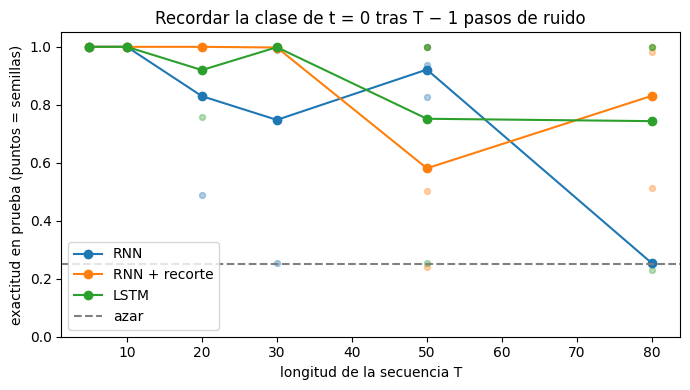

In [41]:
def figura_exactitud(res):
    fig, ax = plt.subplots(figsize=(7, 4))
    for mod, color in [("RNN", "tab:blue"), ("RNN + recorte", "tab:orange"), ("LSTM", "tab:green")]:
        sub = res[res.modelo == mod]
        media = sub.groupby("T").exactitud_prueba.mean()
        ax.plot(media.index, media.values, marker="o", color=color, label=mod)
        ax.scatter(sub["T"], sub.exactitud_prueba, color=color, alpha=0.35, s=18)
    ax.axhline(1 / N_CLASES, color="gray", ls="--", label="azar")
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("longitud de la secuencia T")
    ax.set_ylabel("exactitud en prueba (puntos = semillas)")
    ax.set_title("Recordar la clase de t = 0 tras T − 1 pasos de ruido")
    ax.legend(loc="lower left")
    fig.tight_layout()
    return fig


fig_exactitud = figura_exactitud(resultados)
plt.show()

## 9 · e · Gráfico del gradiente por distancia (resumen sin entrenar)
Repito la medida del Panel A con T = 50 para los cinco casos que usé en el análisis: RNN con radio 0.9, 1.0, 1.5 y 2.0, y la LSTM. Es la figura que acompaña a la tabla de arriba.

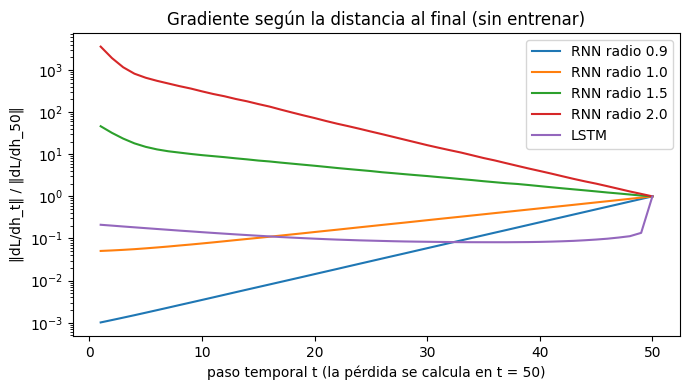

{'RNN radio 0.9': '0.00102', 'RNN radio 1.0': '0.0506', 'RNN radio 1.5': '46.2', 'RNN radio 2.0': '3.58e+03', 'LSTM': '0.212'}


In [42]:
curvas_ini = {}
for etiqueta, nombre, radio in [("RNN radio 0.9", "RNN", 0.9), ("RNN radio 1.0", "RNN", 1.0), ("RNN radio 1.5", "RNN", 1.5),
                                ("RNN radio 2.0", "RNN", 2.0), ("LSTM", "LSTM", 1.0)]:
    acum = []
    for s in SEMILLAS:
        torch.manual_seed(s)
        X, y = generar(256, 50, torch.Generator().manual_seed(100 + s))
        acum.append(normas_gradiente(crear(nombre, radio), X, y))
    curvas_ini[etiqueta] = np.mean(acum, axis=0)

fig_grad, ax = plt.subplots(figsize=(7, 4))
for etiqueta, v in curvas_ini.items():
    ax.semilogy(np.arange(1, 51), v / v[-1], label=etiqueta)
ax.set_xlabel("paso temporal t (la pérdida se calcula en t = 50)")
ax.set_ylabel("‖dL/dh_t‖ / ‖dL/dh_50‖")
ax.set_title("Gradiente según la distancia al final (sin entrenar)")
ax.legend()
plt.tight_layout()
plt.show()
print({k: f"{v[0] / v[-1]:.3g}" for k, v in curvas_ini.items()})

## 9 · f · Guardar tablas y figuras
Guardo los resultados en la carpeta `resultados_s11` para poder descargarlos desde Colab.

In [43]:
resultados.round(5).to_csv(SALIDA / "resultados_entrenamiento_torch.csv", index=False)
resumen.to_csv(SALIDA / "resumen_entrenamiento_torch.csv")
fig_exactitud.savefig(SALIDA / "fig_exactitud_vs_longitud_torch.png", dpi=150)
fig_grad.savefig(SALIDA / "fig_gradiente_por_distancia_torch.png", dpi=150)
print("Guardados en:", sorted(p.name for p in SALIDA.iterdir()))

Guardados en: ['chequeos_hipotesis_torch.csv', 'comparacion_numpy_torch.csv', 'fig_exactitud_vs_longitud_torch.png', 'fig_gradiente_por_distancia_torch.png', 'resultados_entrenamiento_torch.csv', 'resumen_entrenamiento_torch.csv']


# 10 · Panel B: resultados del entrenamiento por longitud
Este panel solo consulta los 54 entrenamientos de la sección 9, así que responde al instante. Muestra la curva de pérdida de cada modelo para la longitud `T` y la semilla elegidas, y la exactitud final de cada uno. Sirve para ver si la pérdida se queda en `ln 4 ≈ 1.386` (azar), que es lo que ocurre cuando el modelo no logra usar la información del primer paso, o si baja.

In [44]:
def panel_b(T, semilla):
    fig, ax = plt.subplots(figsize=(7, 4))
    for etiqueta, color in [("RNN", "tab:blue"), ("RNN + recorte", "tab:orange"), ("LSTM", "tab:green")]:
        curva = CURVAS[(etiqueta, T, semilla)]
        fila = resultados[(resultados.modelo == etiqueta) & (resultados["T"] == T) & (resultados.semilla == semilla)].iloc[0]
        ax.plot(np.arange(len(curva)) * 10, curva, color=color, label=f"{etiqueta} (exactitud {fila.exactitud_prueba:.2f})")
    ax.axhline(np.log(N_CLASES), color="gray", ls="--", label="azar (ln 4)")
    ax.set_xlabel("paso de entrenamiento")
    ax.set_ylabel("pérdida de entrenamiento")
    ax.set_title(f"Curvas de aprendizaje con T = {T}, semilla {semilla}")
    ax.legend()
    plt.tight_layout()
    plt.show()

## 10 · b · Sliders del Panel B
El slider `T` solo permite las longitudes entrenadas y `Semilla` va de 0 a 2.

In [45]:
b_T = widgets.SelectionSlider(options=LONGITUDES, value=LONGITUDES[3], description="T", continuous_update=False)
b_semilla = widgets.IntSlider(value=0, min=0, max=len(SEMILLAS) - 1, description="Semilla", continuous_update=False)
display(widgets.VBox([b_T, b_semilla, widgets.interactive_output(panel_b, {"T": b_T, "semilla": b_semilla})]))

# 11 · Panel C: entrenar en vivo
Para mostrar en la exposición que lo anterior no es una tabla pegada, este panel entrena un modelo con los parámetros que elija, con menos pasos para que tarde unos segundos. Imprime la exactitud en prueba y la razón de gradientes del modelo entrenado, y dibuja la curva de pérdida.

- **Modelo:** RNN o LSTM.
- **Recorte:** activa el recorte de la norma global (solo cambia la RNN en el caso de la explosión).
- **Radio de `W_hh`:** solo se usa con la RNN.
- **Pasos:** con pocos pasos (600) la LSTM puede no alcanzar a converger con `T` grande; no compara con la tabla de la sección 9, que usa 3 000.

In [46]:
c_modelo = widgets.ToggleButtons(options=["RNN", "LSTM"], description="Modelo")
c_T = widgets.SelectionSlider(options=LONGITUDES, value=20, description="T", continuous_update=False)
c_radio = widgets.FloatSlider(value=1.0, min=0.5, max=2.0, step=0.1, description="Radio W_hh")
c_clip = widgets.Checkbox(value=False, description="Recorte de gradiente")
c_pasos = widgets.IntSlider(value=600, min=200, max=3000, step=200, description="Pasos")
c_semilla = widgets.IntSlider(value=0, min=0, max=4, description="Semilla")
c_boton = widgets.Button(description="Entrenar", button_style="primary")
c_salida = widgets.Output()


def al_pulsar(_):
    with c_salida:
        c_salida.clear_output(wait=True)
        t0 = time.time()
        r = entrenar(c_modelo.value, c_T.value, c_semilla.value, clip=c_clip.value, radio=c_radio.value, pasos=c_pasos.value)
        print(f"{c_modelo.value}, T = {c_T.value}, {c_pasos.value} pasos, recorte = {c_clip.value}, radio = {c_radio.value}")
        print(f"exactitud en prueba: {r['exactitud_prueba']:.3f} (azar = {1 / N_CLASES:.2f})")
        print(f"log10(‖dL/dh_1‖ / ‖dL/dh_T‖) del modelo entrenado: {r['log10_ratio_grad']:.2f}")
        print(f"norma máxima del gradiente durante el entrenamiento: {r['norma_grad_max']:.1f}")
        print(f"tiempo: {time.time() - t0:.1f} s")
        plt.figure(figsize=(6, 3))
        plt.plot(np.arange(len(r["curva"])) * 10, r["curva"])
        plt.axhline(np.log(N_CLASES), color="gray", ls="--")
        plt.xlabel("paso de entrenamiento")
        plt.ylabel("pérdida")
        plt.tight_layout()
        plt.show()


c_boton.on_click(al_pulsar)
display(widgets.VBox([c_modelo, c_T, c_radio, c_clip, c_pasos, c_semilla, c_boton, c_salida]))

# 12 · Validación de las hipótesis con los números
Contrasto cada hipótesis del inicio con los resultados de esta ejecución. Cada línea imprime `True` o `False` según se cumpla el criterio, de modo que una hipótesis que no se sostiene con estos datos aparece como falsa. Los criterios son mis umbrales, no vienen de las fuentes.

In [47]:
def media(modelo, T):
    return resultados[(resultados.modelo == modelo) & (resultados["T"] == T)].exactitud_prueba.mean()


def mediana_log(modelo, T):
    return resultados[(resultados.modelo == modelo) & (resultados["T"] == T)].log10_ratio_grad.median()


chequeos = {
    "RNN aprende con T = 5 y T = 10 (media > 0.9)": media("RNN", 5) > 0.9 and media("RNN", 10) > 0.9,
    "RNN con T = 50 queda cerca del azar (media < 0.4)": media("RNN", 50) < 0.4,
    "RNN con T = 80 queda cerca del azar (media < 0.4)": media("RNN", 80) < 0.4,
    "Desvanecimiento en la RNN entrenada, T >= 50 (mediana log10 < -2)": mediana_log("RNN", 50) < -2 and mediana_log("RNN", 80) < -2,
    "LSTM con T = 50 supera a la RNN": media("LSTM", 50) > media("RNN", 50),
    "LSTM con T = 80 supera a la RNN": media("LSTM", 80) > media("RNN", 80),
    "El recorte no devuelve la memoria (RNN + recorte, T = 80, media < 0.5)": media("RNN + recorte", 80) < 0.5,
    "La LSTM falla en alguna corrida (hay excepción)": bool((resultados[resultados.modelo == "LSTM"].exactitud_prueba < 0.5).any()),
    "La RNN acierta en alguna corrida con T >= 20 (no falla siempre)": bool(((resultados.modelo == "RNN") & (resultados["T"] >= 20) & (resultados.exactitud_prueba > 0.9)).any()),
}
for texto, ok in chequeos.items():
    print(f"{ok!s:<5} · {texto}")

True  · RNN aprende con T = 5 y T = 10 (media > 0.9)
False · RNN con T = 50 queda cerca del azar (media < 0.4)
True  · RNN con T = 80 queda cerca del azar (media < 0.4)
True  · Desvanecimiento en la RNN entrenada, T >= 50 (mediana log10 < -2)
False · LSTM con T = 50 supera a la RNN
True  · LSTM con T = 80 supera a la RNN
False · El recorte no devuelve la memoria (RNN + recorte, T = 80, media < 0.5)
True  · La LSTM falla en alguna corrida (hay excepción)
True  · La RNN acierta en alguna corrida con T >= 20 (no falla siempre)


# 13 · Comparación con la ejecución en NumPy
Antes de este notebook hice el mismo experimento con una RNN y una LSTM escritas a mano en NumPy (BPTT manual, verificado con diferencias finitas, error relativo máximo 1.6e-7) y las mismas semillas, longitudes y parámetros. PyTorch inicializa los pesos de otra manera y usa otro generador de números aleatorios, así que no espero las mismas cifras, pero sí el mismo patrón. Dejo aquí la media de exactitud del experimento en NumPy como referencia, para que cualquiera la compare con la de arriba.

In [48]:
EFERENCIA_NUMPY = {
    ("RNN", 5): 1.0, ("RNN", 10): 0.9998, ("RNN", 20): 0.5777, ("RNN", 30): 0.6903, ("RNN", 50): 0.2597, ("RNN", 80): 0.3312,
    ("RNN + recorte", 5): 1.0, ("RNN + recorte", 10): 1.0, ("RNN + recorte", 20): 0.615, ("RNN + recorte", 30): 0.7488,
    ("RNN + recorte", 50): 0.5037, ("RNN + recorte", 80): 0.3232,
    ("LSTM", 5): 1.0, ("LSTM", 10): 1.0, ("LSTM", 20): 1.0, ("LSTM", 30): 0.9998, ("LSTM", 50): 0.7455, ("LSTM", 80): 1.0,
}
comparacion = resumen.exactitud_media.rename("torch").to_frame()
comparacion["numpy"] = [REFERENCIA_NUMPY[i] for i in comparacion.index]
comparacion["diferencia"] = (comparacion.torch - comparacion.numpy).round(3)
display(comparacion.round(3))
print("Diferencia absoluta media:", round(comparacion.diferencia.abs().mean(), 3))

torch  numpy  diferencia
modelo        T                           
LSTM          5   1.000  1.000       0.000
              10  1.000  1.000       0.000
              20  0.920  1.000      -0.080
              30  0.999  1.000      -0.001
              50  0.752  0.746       0.006
              80  0.744  1.000      -0.256
RNN           5   1.000  1.000       0.000
              10  1.000  1.000       0.000
              20  0.830  0.578       0.252
              30  0.748  0.690       0.058
              50  0.922  0.260       0.662
              80  0.254  0.331      -0.077
RNN + recorte 5   1.000  1.000       0.000
              10  1.000  1.000       0.000
              20  1.000  0.615       0.385
              30  0.998  0.749       0.249
              50  0.581  0.504       0.077
              80  0.831  0.323       0.508

Diferencia absoluta media: 0.145


## 13 · b · Cómo leer la comparación
Con 3 semillas, la exactitud de un caso individual cambia mucho de una implementación a otra (en la tabla se ve en T = 20, 30 y 50). Lo comparable es el patrón. Con T = 5 y 10 ambos modelos aprenden en las dos implementaciones. Con T ≥ 20 el resultado depende mucho de la semilla en las dos, y la ventaja de la LSTM sobre la RNN es menor en PyTorch que en NumPy. No fuerzo que coincidan: lo reporto como diferencia entre implementaciones.

# 14 · Qué dicen las fuentes y qué no
Cada afirmación del trabajo se apoya en un artículo de IEEE Xplore (2022 a 2026), cuyo PDF leí en las partes que cito. Lo que sale de mis experimentos lo marco como propio.

| Afirmación | Fuente | Dónde |
|---|---|---|
| El gradiente se desvanece o explota por el producto repetido de jacobianos en BPTT, y es peor con activaciones que "aplastan" como `tanh` | Ceni (2025) | Introducción, p. 10794 |
| El problema se reconoció primero en RNN y la inicialización ortogonal ayuda pero no lo resuelve por sí sola | Ceni (2025) | Introducción |
| La memoria a largo plazo de una RNN depende de los autovalores de `W_hh`; con autovalores que no pasan de 1 la información decae | Dou y Principe (2023) | Secciones I a III |
| Las RNN de Elman son difíciles de entrenar, muy dependientes de la inicialización, y tienen fronteras de bifurcación en el espacio de parámetros | Rehmer y Kroll (2022) | Introducción, Sec. V y VII |
| En unidades con compuertas el gradiente también puede desvanecerse; no son inmunes | Rehmer y Kroll (2022) | Resumen e introducción |
| El gradiente que se desvanece o explota es la causa principal de la dificultad de aprender dependencias largas, y las compuertas (LSTM) buscan mantener un flujo de error constante | He et al. (2022) | Introducción |
| Las compuertas de LSTM y GRU se crearon para aliviar el desvanecimiento del gradiente | Shan et al. (2023) | Introducción |
| Inicializar el sesgo de la compuerta de olvido en 1 o 2 facilita el flujo del gradiente | Tolić et al. (2024), que cita a Jozefowicz et al. | p. 115221 |
| La tarea de recordar la clase del primer paso, el ruido, `T`, los hiperparámetros y las cifras de exactitud | **Propios** | Secciones 4, 9 y 12 |

**Límites de lo que se puede decir con esto.** La tarea es sintética y la diseñé yo; 3 semillas dan estimaciones ruidosas; no evalué GRU; los hiperparámetros se ajustaron con la misma familia de tarea; y las cifras de PyTorch difieren de las de NumPy en los casos individuales. No afirmo que la RNN no pueda aprender con `T` grande: en otros diseños se ha logrado (Ceni, 2025).

# 15 · Interpretación de la ejecución en Colab
Ejecuté este mismo notebook dos veces en Google Colab, con las mismas semillas y parámetros, y las cifras no coincidieron. Con 3 semillas, un caso que en una ejecución llegó a 1.0 en otra quedó en 0.25 (por ejemplo, la RNN con T = 80 tuvo media 0.64 en la primera ejecución y 0.25 en la segunda). La causa probable es que PyTorch en CPU no da exactamente los mismos números en máquinas distintas, y que estas redes amplifican esas diferencias mínimas; no lo comprobé. Por eso la celda siguiente calcula el resumen con **los datos de esta ejecución** y la lectura de abajo evita citar cifras de una ejecución concreta.

In [49]:
filas = []
for (modelo, T), g in resultados.groupby(["modelo", "T"]):
    filas.append({"modelo": modelo, "T": T, "exactitud_media": g.exactitud_prueba.mean(),
                  "corridas_>=0.9": f"{int((g.exactitud_prueba >= 0.9).sum())}/{len(g)}",
                  "mediana_log10_ratio": g.log10_ratio_grad.median()})
resumen_lectura = pd.DataFrame(filas).round(2)
display(resumen_lectura)
largas = resultados[resultados["T"] >= 20]
for modelo in ["RNN", "RNN + recorte", "LSTM"]:
    sub = largas[largas.modelo == modelo]
    print(f"{modelo:<14} T >= 20: {int((sub.exactitud_prueba >= 0.9).sum())} de {len(sub)} corridas con exactitud >= 0.9")

,modelo,T,exactitud_media,corridas_>=0.9,mediana_log10_ratio
0,LSTM,5,1.00,3/3,-0.50
1,LSTM,10,1.00,3/3,-1.27
2,LSTM,20,0.92,2/3,-0.91
3,LSTM,30,1.00,3/3,-0.54
4,LSTM,50,0.75,2/3,-0.33
5,LSTM,80,0.74,2/3,-0.41
6,RNN,5,1.00,3/3,0.32
7,RNN,10,1.00,3/3,0.16
8,RNN,20,0.83,2/3,-0.22
9,RNN,30,0.75,2/3,0.18


RNN            T >= 20: 6 de 12 corridas con exactitud >= 0.9
RNN + recorte  T >= 20: 9 de 12 corridas con exactitud >= 0.9
LSTM           T >= 20: 9 de 12 corridas con exactitud >= 0.9


## 15 · b · Lectura de los resultados
Lo que se repitió en las dos ejecuciones que hice, y que se puede comprobar en la tabla de arriba:

- **Con T = 5 y 10 todos los modelos aprenden** en las 3 semillas.
- **Con T ≥ 20 ni la RNN ni la LSTM aprenden siempre.** Cada modelo falla en alguna semilla. En particular, la LSTM con la semilla 1 quedó cerca del azar en T = 50 y T = 80 en las dos ejecuciones, así que la LSTM tampoco es inmune, como señalan Rehmer y Kroll (2022).
- **Cuando un modelo falla, el gradiente hacia el primer paso suele ser mucho menor:** en la RNN, de unos 1e-5 a 1e-30 veces el del último paso; en la LSTM, de 1e-0 a 1e-6. Pero no separa los casos por completo: hubo RNN que aprendieron con una razón de hasta 1e-8. La razón de gradientes se mide en el modelo ya entrenado y es una pista, no una prueba de la causa del fallo.
- **El recorte de gradiente no resuelve el problema:** limita la norma, y los casos con T grande siguen fallando en alguna semilla.

Lo que **no** se sostiene con estos datos: que la RNN falle de forma consistente desde T ≥ 50, o que la LSTM la supere de forma estable. Entre una ejecución y otra, la media de la RNN con T = 50 pasó de 0.64 a 0.92, y la de la LSTM se mantuvo en 0.75.

**Conclusión.** Se observa el desvanecimiento del gradiente (razones de gradiente de hasta 1e-30 en RNN que fallan) y que el entrenamiento se vuelve dependiente de la semilla desde T = 20 en los dos modelos. Con 3 semillas no se puede decir cuál de los dos modelos es mejor con secuencias largas; harían falta más semillas.

# 16 · Guardar y descargar los resultados
Guardo en `resultados_s11` los chequeos de la sección 12 y la comparación con NumPy de la sección 13, que se suman a las tablas y figuras de la sección 9. Luego comprimo la carpeta en `resultados_s11.zip` y la descargo desde Colab. El archivo se baja a la carpeta de descargas del navegador y desde ahí se puede copiar a `resultados/google colab` del curso.

In [50]:
pd.DataFrame({"chequeo": list(chequeos), "se_cumple": list(chequeos.values())}).to_csv(SALIDA / "chequeos_hipotesis_torch.csv", index=False)
comparacion.to_csv(SALIDA / "comparacion_numpy_torch.csv")
print("Archivos en la carpeta:", sorted(p.name for p in SALIDA.iterdir()))

Archivos en la carpeta: ['chequeos_hipotesis_torch.csv', 'comparacion_numpy_torch.csv', 'fig_exactitud_vs_longitud_torch.png', 'fig_gradiente_por_distancia_torch.png', 'resultados_entrenamiento_torch.csv', 'resumen_entrenamiento_torch.csv']


## 16 · b · Comprimir y descargar
Si Colab muestra un aviso de descarga, hay que permitirlo en el navegador. Fuera de Colab (por ejemplo en Jupyter local) la celda solo crea el `.zip` y avisa dónde quedó.

In [ ]:
import shutil

ruta_zip = shutil.make_archive("resultados_s11", "zip", SALIDA)
print("Archivo creado:", ruta_zip)
try:
    from google.colab import files
    files.download(ruta_zip)
except ImportError:
    print("No se está ejecutando en Colab: el .zip quedó en", Path(ruta_zip).resolve())

# 17 · Referencias
- Ceni, A. (2025). Random orthogonal additive filters: A solution to the vanishing/exploding gradient of deep neural networks. *IEEE Transactions on Neural Networks and Learning Systems*. https://doi.org/10.1109/TNNLS.2025.3538924
- Dou, R., y Principe, J. C. (2023). Dynamic analysis and an eigen initializer for recurrent neural networks. *2023 International Joint Conference on Neural Networks (IJCNN)*. https://doi.org/10.1109/IJCNN54540.2023.10191986
- He, W., et al. (2022). Subtraction gates: Another way to learn long-term dependencies in recurrent neural networks. *IEEE Transactions on Neural Networks and Learning Systems*. https://doi.org/10.1109/TNNLS.2020.3043752
- Rehmer, A., y Kroll, A. (2022). The effect of the forget gate on bifurcation boundaries and dynamics in recurrent neural networks and its implications for gradient-based optimization. *2022 International Joint Conference on Neural Networks (IJCNN)*. https://doi.org/10.1109/IJCNN55064.2022.9892458
- Shan, F., et al. (2023). DRRNets: Dynamic recurrent routing via low-rank regularization in recurrent neural networks. *IEEE Transactions on Neural Networks and Learning Systems*. https://doi.org/10.1109/TNNLS.2021.3105818
- Tolić, D., et al. (2024). Chrono initialized LSTM networks with layer normalization. *IEEE Access*. https://doi.org/10.1109/ACCESS.2024.3445329
- Clase 11 del curso INF659 (material de la semana 11), para la formulación de BPTT, el recorte de gradiente y la LSTM.